# 07 · Randomness & Simulation

**Module 02 — NumPy & Numerical Computing**

---

## What you will learn

1. The modern `Generator` API, and why the legacy `np.random.seed` is a liability.
2. Reproducibility that survives parallelism, via `SeedSequence` and `spawn`.
3. The distributions you will actually draw from, and when each applies.
4. Sampling: with and without replacement, weighted, permutations.
5. **Monte Carlo** — answering questions that have no closed form.
6. **The bootstrap** — confidence intervals without any distributional assumption.

**Estimated time:** 75 minutes

> This notebook is the bridge into the statistics half of the course. Everything
> in Modules 07–09 either uses these tools or is validated against them.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from dstoolkit import setup_plot_style
from dstoolkit.plotting import COLORS

setup_plot_style()

## 1. The `Generator` API

NumPy has two random systems. Use the newer one.

In [2]:
# ✘ Legacy: one hidden global state shared by every library in the process.
np.random.seed(42)
legacy = np.random.rand(3)

# ✔ Modern: an explicit object you own and pass around.
rng = np.random.default_rng(seed=42)
modern = rng.random(3)

print(f"legacy np.random.rand : {legacy.round(4)}")
print(f"modern rng.random     : {modern.round(4)}")

legacy np.random.rand : [0.3745 0.9507 0.732 ]
modern rng.random     : [0.774  0.4389 0.8586]


### Why the global state is a problem

`np.random.seed` sets state that *every* library shares. If scikit-learn, or a
plotting call, or a colleague's helper function draws a number between your
seed and your draw, your "reproducible" result silently changes.

In [3]:
def third_party_function():
    """Stands in for any library that happens to use the global generator."""
    return np.random.rand(5)


np.random.seed(42)
first_run = np.random.rand(3)

np.random.seed(42)
third_party_function()          # someone else drew numbers in between
second_run = np.random.rand(3)

print(f"first run  : {first_run.round(4)}")
print(f"second run : {second_run.round(4)}")
print(f"identical  : {np.array_equal(first_run, second_run)}   ← reproducibility broken")

first run  : [0.3745 0.9507 0.732 ]
second run : [0.156  0.0581 0.8662]
identical  : False   ← reproducibility broken


In [4]:
# The Generator has no such problem: its state is private to the object.
rng = np.random.default_rng(42)
first_run = rng.random(3)

rng = np.random.default_rng(42)
third_party_function()          # cannot touch our generator
second_run = rng.random(3)

print(f"first run  : {first_run.round(4)}")
print(f"second run : {second_run.round(4)}")
print(f"identical  : {np.array_equal(first_run, second_run)}   ← safe")

first run  : [0.774  0.4389 0.8586]
second run : [0.774  0.4389 0.8586]
identical  : True   ← safe


> [!TIP]
> **Create one `Generator` at the top of your script or notebook and pass it
> down.** Functions that need randomness should take `rng` as a parameter
> rather than reaching for a global. This is the same "no hidden state"
> principle as Module 01's advice about pure functions.

In [5]:
def simulate_returns(rng: np.random.Generator, n_days: int = 252) -> np.ndarray:
    """Simulate daily returns. The generator is injected, never global."""
    return rng.normal(loc=0.0005, scale=0.01, size=n_days)


rng = np.random.default_rng(seed=7)
print(f"first call  : {simulate_returns(rng, 3).round(5)}")
print(f"second call : {simulate_returns(rng, 3).round(5)}   ← advances, as it should")

rng = np.random.default_rng(seed=7)
print(f"after reset : {simulate_returns(rng, 3).round(5)}   ← reproducible")

first call  : [ 0.00051  0.00349 -0.00224]
second call : [-0.00841 -0.00405 -0.00942]   ← advances, as it should
after reset : [ 0.00051  0.00349 -0.00224]   ← reproducible


### Independent streams for parallel work

Splitting a single generator across processes by seeding each with `seed + i` is
a real mistake — nearby seeds can produce correlated streams. `SeedSequence`
spawning gives provably independent children.

In [6]:
parent = np.random.SeedSequence(42)
children = parent.spawn(4)
workers = [np.random.default_rng(child) for child in children]

print("Four independent streams from one reproducible parent:")
for i, worker_rng in enumerate(workers):
    print(f"  worker {i} : {worker_rng.random(4).round(4)}")

# Re-spawning from the same parent reproduces them exactly.
reproduced = [np.random.default_rng(c) for c in np.random.SeedSequence(42).spawn(4)]
print(f"\nreproducible across runs : "
      f"{np.array_equal(reproduced[0].random(4), np.random.default_rng(children[0]).random(4))}")

Four independent streams from one reproducible parent:
  worker 0 : [0.9167 0.911  0.8766 0.3093]
  worker 1 : [0.4675 0.0464 0.5955 0.1073]
  worker 2 : [0.0712 0.7102 0.0718 0.3193]
  worker 3 : [0.7639 0.9713 0.713  0.003 ]

reproducible across runs : True


## 2. The distributions you will use

Each models a different kind of process. Choosing the right one is a modelling
decision, not a technical one.

In [7]:
rng = np.random.default_rng(seed=42)
n = 10_000

distributions = {
    "uniform(0, 1)": rng.random(n),
    "normal(0, 1)": rng.normal(0, 1, n),
    "lognormal(0, 0.5)": rng.lognormal(0, 0.5, n),
    "exponential(scale=1)": rng.exponential(1, n),
    "binomial(n=20, p=0.3)": rng.binomial(20, 0.3, n),
    "poisson(lam=3)": rng.poisson(3, n),
}

print(f"{'distribution':<24} {'mean':>8} {'std':>8} {'min':>8} {'max':>8}")
print("-" * 62)
for name, sample in distributions.items():
    print(f"{name:<24} {sample.mean():>8.3f} {sample.std():>8.3f} "
          f"{sample.min():>8.3f} {sample.max():>8.3f}")

distribution                 mean      std      min      max
--------------------------------------------------------------
uniform(0, 1)               0.497    0.288    0.000    1.000
normal(0, 1)                0.014    1.002   -3.888    4.151
lognormal(0, 0.5)           1.146    0.614    0.171    6.304
exponential(scale=1)        1.007    0.998    0.000    8.431
binomial(n=20, p=0.3)       5.993    2.041    0.000   15.000
poisson(lam=3)              3.008    1.743    0.000   12.000


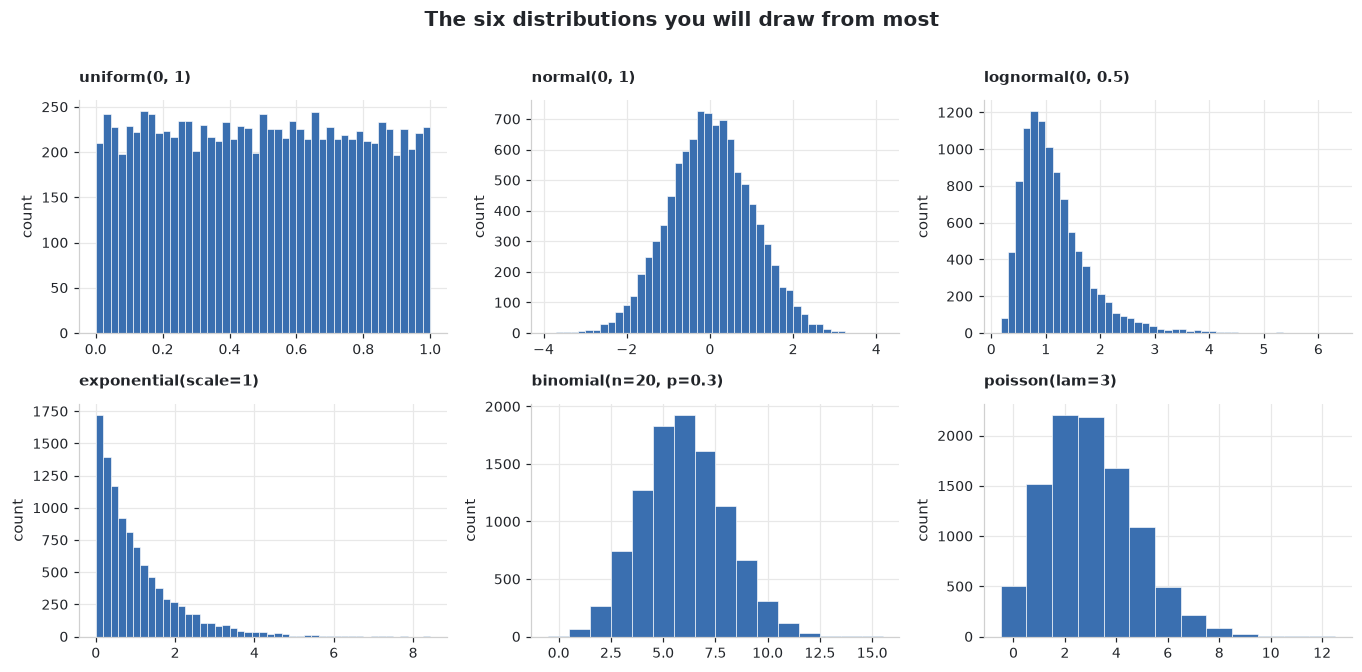

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12.5, 6))

for ax, (name, sample) in zip(axes.ravel(), distributions.items(), strict=True):
    is_discrete = name.startswith(("binomial", "poisson"))
    bins = np.arange(sample.min(), sample.max() + 2) - 0.5 if is_discrete else 45

    ax.hist(sample, bins=bins, color=COLORS["primary"],
            edgecolor="white", linewidth=0.4)
    ax.set_title(name, fontsize=10)
    ax.set_ylabel("count")

fig.suptitle("The six distributions you will draw from most", fontsize=13, y=1.01)
fig.tight_layout()
plt.show()

### Which one, and when

| Distribution | Models | You will meet it in |
| :--- | :--- | :--- |
| **Uniform** | "any value in a range, equally likely" | random initialisation, shuffling |
| **Normal** | sums of many small effects (CLT) | measurement error, residuals |
| **Lognormal** | quantities that are *products* of effects | income, spend, session length |
| **Exponential** | waiting time between events | churn, time-to-failure |
| **Binomial** | successes in *n* independent trials | conversions out of visitors |
| **Poisson** | count of events in a fixed window | arrivals per hour, defects per batch |

> [!NOTE]
> Customer spend is **lognormal**, not normal — which is why the mean sat well
> above the median back in Module 01's very first analysis. Recognising the
> generating process tells you which summary statistic is honest.

## 3. Sampling

In [9]:
rng = np.random.default_rng(seed=42)
population = np.array(["A", "B", "C", "D", "E"])

print(f"with replacement    : {rng.choice(population, 8)}")
print(f"without replacement : {rng.choice(population, 4, replace=False)}")
print(f"weighted            : {rng.choice(population, 8, p=[0.6, 0.2, 0.1, 0.05, 0.05])}")

with replacement    : ['A' 'D' 'D' 'C' 'C' 'E' 'A' 'D']
without replacement : ['A' 'C' 'E' 'D']
weighted            : ['A' 'A' 'A' 'D' 'B' 'C' 'A' 'A']


In [10]:
# Permutation vs shuffle: one returns a new array, the other works in place.
arr = np.arange(10)

permuted = rng.permutation(arr)
print(f"original after permutation : {arr}   ← untouched")
print(f"permuted                   : {permuted}")

rng.shuffle(arr)                          # in place, returns None
print(f"original after shuffle     : {arr}   ← modified")

original after permutation : [0 1 2 3 4 5 6 7 8 9]   ← untouched
permuted                   : [6 8 1 5 4 0 7 9 2 3]
original after shuffle     : [3 2 6 5 1 4 8 0 7 9]   ← modified


In [11]:
# A train/test split, built from a permutation. This is what scikit-learn does.
n_samples = 1000
X = rng.normal(size=(n_samples, 3))
y = rng.integers(0, 2, n_samples)

indices = rng.permutation(n_samples)
split = int(0.8 * n_samples)
train_idx, test_idx = indices[:split], indices[split:]

print(f"train : {len(train_idx)} samples")
print(f"test  : {len(test_idx)} samples")
print(f"no overlap : {len(set(train_idx) & set(test_idx)) == 0}")
print(f"class balance — train {y[train_idx].mean():.3f}, test {y[test_idx].mean():.3f}")

train : 800 samples
test  : 200 samples
no overlap : True
class balance — train 0.485, test 0.480


## 4. Monte Carlo

When a quantity is hard to derive analytically, **simulate it**. Draw many
random outcomes and average. The estimate converges at a rate of `1/√n` — which
is slow, but it works for problems where no formula exists.

In [12]:
def estimate_pi(rng: np.random.Generator, n_points: int) -> float:
    """Estimate π by sampling points in the unit square.

    The fraction landing inside the quarter circle approaches π/4.
    """
    points = rng.random((n_points, 2))
    inside = (points**2).sum(axis=1) <= 1.0
    return 4.0 * inside.mean()


rng = np.random.default_rng(seed=42)

print(f"{'n points':>12} {'estimate':>12} {'error':>12}")
print("-" * 38)
for n_points in [100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000]:
    estimate = estimate_pi(rng, n_points)
    print(f"{n_points:>12,} {estimate:>12.6f} {abs(estimate - np.pi):>12.6f}")

print(f"\ntrue π = {np.pi:.6f}")
print("→ error falls like 1/√n: 100× more points buys only 10× more accuracy.")

    n points     estimate        error
--------------------------------------
         100     3.040000     0.101593
       1,000     3.116000     0.025593
      10,000     3.154400     0.012807
     100,000     3.147160     0.005567
   1,000,000     3.142196     0.000603


  10,000,000     3.141560     0.000033

true π = 3.141593
→ error falls like 1/√n: 100× more points buys only 10× more accuracy.


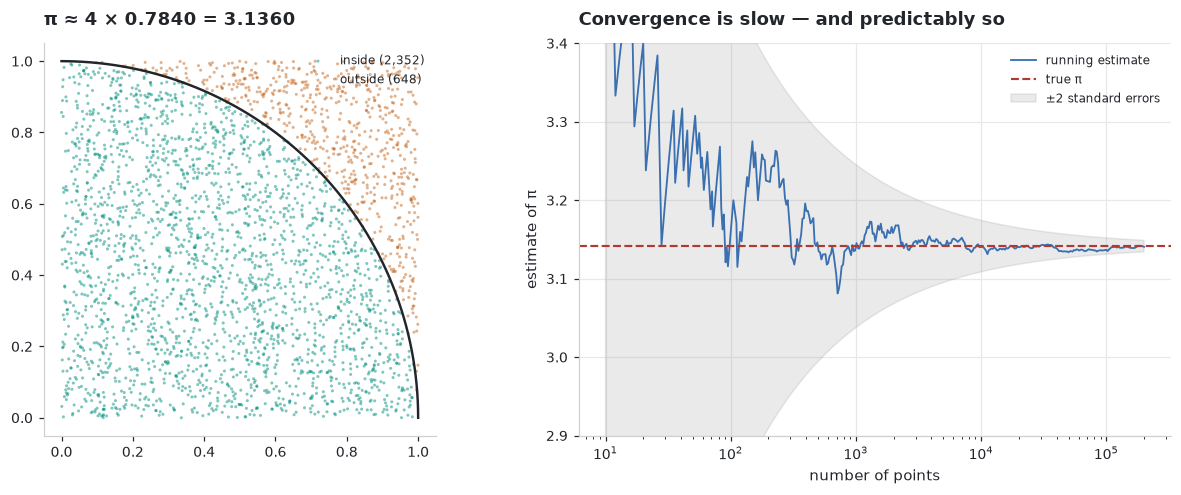

In [13]:
fig, (ax_scatter, ax_conv) = plt.subplots(1, 2, figsize=(11.5, 4.6))

# --- Left: what the simulation is doing -----------------------------------
rng_plot = np.random.default_rng(seed=1)
points = rng_plot.random((3000, 2))
inside = (points**2).sum(axis=1) <= 1.0

ax_scatter.scatter(points[inside, 0], points[inside, 1], s=4,
                   color=COLORS["teal"], alpha=0.5, edgecolors="none",
                   label=f"inside ({inside.sum():,})")
ax_scatter.scatter(points[~inside, 0], points[~inside, 1], s=4,
                   color=COLORS["accent"], alpha=0.5, edgecolors="none",
                   label=f"outside ({(~inside).sum():,})")

theta = np.linspace(0, np.pi / 2, 200)
ax_scatter.plot(np.cos(theta), np.sin(theta), color=COLORS["text"], linewidth=1.6)

ax_scatter.set_aspect("equal")
ax_scatter.set_title(f"π ≈ 4 × {inside.mean():.4f} = {4 * inside.mean():.4f}")
ax_scatter.legend(loc="upper right", fontsize=8)
ax_scatter.grid(False)

# --- Right: convergence, with the 1/√n envelope ---------------------------
rng_conv = np.random.default_rng(seed=2)
n_max = 200_000
draws = rng_conv.random((n_max, 2))
inside_cumulative = np.cumsum((draws**2).sum(axis=1) <= 1.0)
counts = np.arange(1, n_max + 1)
running_estimate = 4 * inside_cumulative / counts

sample_at = np.unique(np.logspace(1, np.log10(n_max), 400).astype(int))
ax_conv.plot(sample_at, running_estimate[sample_at - 1],
             color=COLORS["primary"], linewidth=1.2, label="running estimate")
ax_conv.axhline(np.pi, color=COLORS["danger"], linestyle="--",
                linewidth=1.4, label="true π")

# The theoretical ±1/√n envelope, scaled by the standard deviation of the estimator.
envelope = 4 * np.sqrt(np.pi / 4 * (1 - np.pi / 4)) / np.sqrt(sample_at)
ax_conv.fill_between(sample_at, np.pi - 2 * envelope, np.pi + 2 * envelope,
                     color=COLORS["muted"], alpha=0.18,
                     label="±2 standard errors")

ax_conv.set_xscale("log")
ax_conv.set_xlabel("number of points")
ax_conv.set_ylabel("estimate of π")
ax_conv.set_title("Convergence is slow — and predictably so")
ax_conv.set_ylim(2.9, 3.4)
ax_conv.legend(fontsize=8)

fig.tight_layout()
plt.show()

### A question with no easy formula

*"A checkout page converts at 12%. If 40 people visit, what is the probability
that at least 8 convert?"* This one does have a closed form — which makes it a
good way to check that simulation gives the right answer.

In [14]:
rng = np.random.default_rng(seed=42)

n_visitors, conversion_rate, threshold = 40, 0.12, 8
n_simulations = 500_000

conversions = rng.binomial(n_visitors, conversion_rate, n_simulations)
simulated = (conversions >= threshold).mean()

from scipy import stats

exact = 1 - stats.binom.cdf(threshold - 1, n_visitors, conversion_rate)

print(f"simulated probability : {simulated:.5f}")
print(f"exact (binomial CDF)  : {exact:.5f}")
print(f"difference            : {abs(simulated - exact):.5f}")
print(f"\n→ agreement to ~3 decimals with 500k draws, as 1/√n predicts.")

simulated probability : 0.09960
exact (binomial CDF)  : 0.09963
difference            : 0.00003

→ agreement to ~3 decimals with 500k draws, as 1/√n predicts.


## 5. The bootstrap

The bootstrap estimates the uncertainty of *any* statistic by resampling the
data you already have, with replacement. It needs **no assumption** about the
underlying distribution — which is why it works for medians, ratios, and
correlations where classical formulas are awkward or nonexistent.

In [15]:
def bootstrap_ci(
    data: np.ndarray,
    statistic=np.mean,
    *,
    n_resamples: int = 10_000,
    confidence: float = 0.95,
    rng: np.random.Generator | None = None,
) -> tuple[float, float, float]:
    """Percentile bootstrap confidence interval for any statistic.

    Parameters
    ----------
    data : ndarray
        The observed sample.
    statistic : callable, default np.mean
        Any function mapping a 1-D sample to a scalar.
    n_resamples : int, default 10_000
        Number of bootstrap resamples.
    confidence : float, default 0.95
        Desired coverage.
    rng : Generator, optional
        Injected for reproducibility.

    Returns
    -------
    (point_estimate, ci_low, ci_high)
    """
    if rng is None:
        rng = np.random.default_rng()

    n = len(data)
    # Draw all resamples at once: shape (n_resamples, n). Vectorised, not looped.
    resample_idx = rng.integers(0, n, size=(n_resamples, n))
    resamples = data[resample_idx]

    estimates = statistic(resamples, axis=1)

    alpha = 1 - confidence
    low, high = np.percentile(estimates, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(statistic(data)), float(low), float(high)


# Right-skewed data — the case where the normal-theory interval is questionable.
rng = np.random.default_rng(seed=42)
spend = rng.lognormal(mean=4.0, sigma=0.8, size=300)

estimate, low, high = bootstrap_ci(spend, np.mean, rng=rng)
print(f"sample mean          : ${estimate:7.2f}")
print(f"95% bootstrap CI     : [${low:7.2f}, ${high:7.2f}]")

# The median has no simple closed-form standard error — the bootstrap does not care.
estimate, low, high = bootstrap_ci(spend, np.median, rng=rng)
print(f"\nsample median        : ${estimate:7.2f}")
print(f"95% bootstrap CI     : [${low:7.2f}, ${high:7.2f}]")

sample mean          : $  71.18
95% bootstrap CI     : [$  63.74, $  79.46]

sample median        : $  50.93
95% bootstrap CI     : [$  46.59, $  58.27]


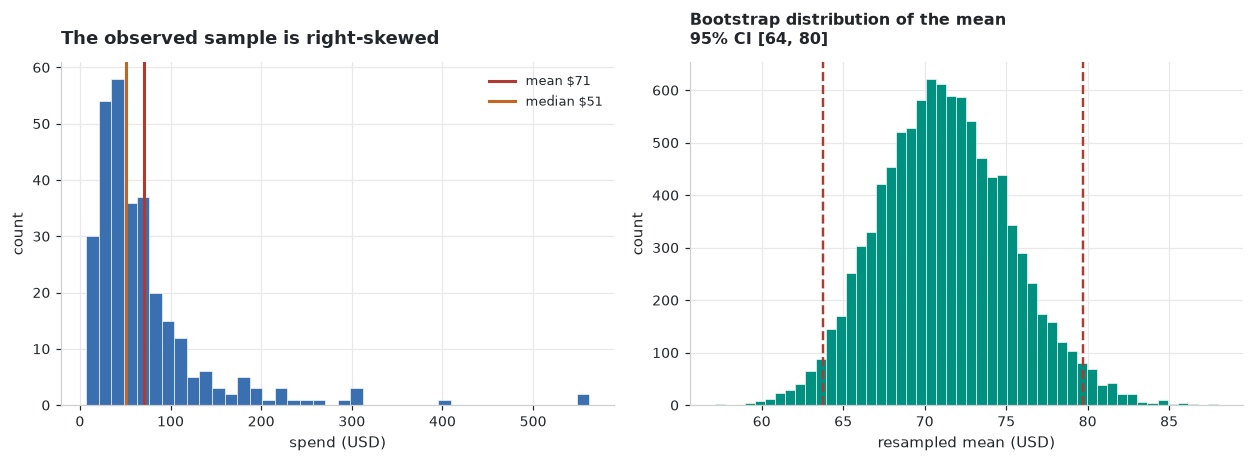

In [16]:
fig, (ax_data, ax_boot) = plt.subplots(1, 2, figsize=(11.5, 4.3))

ax_data.hist(spend, bins=40, color=COLORS["primary"],
             edgecolor="white", linewidth=0.4)
ax_data.axvline(np.mean(spend), color=COLORS["danger"], linewidth=2,
                label=f"mean ${np.mean(spend):.0f}")
ax_data.axvline(np.median(spend), color=COLORS["accent"], linewidth=2,
                label=f"median ${np.median(spend):.0f}")
ax_data.set_title("The observed sample is right-skewed")
ax_data.set_xlabel("spend (USD)")
ax_data.set_ylabel("count")
ax_data.legend(fontsize=8.5)

# The bootstrap distribution of the mean.
resample_idx = rng.integers(0, len(spend), size=(10_000, len(spend)))
boot_means = spend[resample_idx].mean(axis=1)
low, high = np.percentile(boot_means, [2.5, 97.5])

ax_boot.hist(boot_means, bins=50, color=COLORS["teal"],
             edgecolor="white", linewidth=0.4)
ax_boot.axvline(low, color=COLORS["danger"], linestyle="--", linewidth=1.6)
ax_boot.axvline(high, color=COLORS["danger"], linestyle="--", linewidth=1.6)
ax_boot.set_title(f"Bootstrap distribution of the mean\n95% CI [{low:.0f}, {high:.0f}]",
                  fontsize=10.5)
ax_boot.set_xlabel("resampled mean (USD)")
ax_boot.set_ylabel("count")

fig.tight_layout()
plt.show()

> [!NOTE]
> Notice the bootstrap distribution of the **mean** is close to normal even
> though the data is strongly skewed. That is the Central Limit Theorem
> appearing on its own, and Module 07 develops it properly.

In [17]:
# Validate against SciPy's implementation.
from scipy.stats import bootstrap as scipy_bootstrap

scipy_result = scipy_bootstrap(
    (spend,), np.mean, n_resamples=10_000, confidence_level=0.95,
    method="percentile", random_state=42,
)

ours_low, ours_high = np.percentile(boot_means, [2.5, 97.5])
print(f"our CI   : [{ours_low:.3f}, {ours_high:.3f}]")
print(f"scipy CI : [{scipy_result.confidence_interval.low:.3f}, "
      f"{scipy_result.confidence_interval.high:.3f}]")
print(f"\nagree to within 1% : "
      f"{abs(ours_low - scipy_result.confidence_interval.low) / ours_low < 0.01}")

our CI   : [63.778, 79.723]
scipy CI : [63.677, 79.464]

agree to within 1% : True


## 6. Exercises

### Exercise 7.1 — Break and fix reproducibility

Write a function that draws random numbers using the **legacy** API and show
that calling an unrelated function between the seed and the draw changes the
result. Then rewrite it with an injected `Generator` and show it cannot happen.

### Exercise 7.2 — Choose the distribution

For each, name the distribution and justify it in one line:

1. Number of support tickets arriving per hour.
2. Time between two consecutive tickets.
3. Whether each of 500 emails gets opened.
4. Total revenue per customer over a year.
5. Measurement error of a well-calibrated sensor.

### Exercise 7.3 — The birthday problem

Estimate by simulation the probability that at least two people in a group of
`k` share a birthday, for `k` from 2 to 60. Plot it, and find the smallest `k`
where the probability exceeds 50%. Compare against the exact formula.

### Exercise 7.4 — Bootstrap a difference

Two groups, `a` and `b`, of customer spend. Bootstrap a 95% confidence interval
for the **difference in medians**. Does it contain zero? Explain what that does
and does not let you claim.

### Exercise 7.5 — Sample size by simulation

A page converts at 10%. You want to detect a lift to 11% with 80% power at
α = 0.05. Estimate the required sample size per arm **by simulation**: for a
grid of sample sizes, simulate 2000 A/B tests and record how often the test
reaches significance. This is the core of Module 09.

## Key takeaways

- Use **`np.random.default_rng(seed)`**. The legacy `np.random.seed` shares one
  global state and its reproducibility is fragile.
- **Inject the generator** into functions rather than reaching for a global —
  the same principle as pure functions in Module 01.
- For parallel work use **`SeedSequence.spawn`**, never `seed + i`.
- Match the **distribution to the generating process**: counts → Poisson,
  waiting times → Exponential, multiplicative quantities → Lognormal.
- **Monte Carlo** answers questions with no closed form; its error shrinks like
  **1/√n**, so 100× the effort buys 10× the accuracy.
- **The bootstrap** gives a confidence interval for any statistic with no
  distributional assumption — resample with replacement and take percentiles.
- Vectorise the resampling (`rng.integers(0, n, size=(B, n))`) rather than
  looping.

---

**Next:** [08 · Performance & Memory](08_performance_and_memory.ipynb) — strides,
contiguity, in-place operations, and knowing when NumPy has run out of road.